# **Introduction**


Data comes from many sources: sensor measurements, events, text, images, and videos. 

- The Internet of Things (IoT) is spewing out streams of information. Much of this data is unstructured: 

- images are a collection of pixels, with each pixel containing RGB
(red, green, blue) color information. 

- Texts are sequences of words and nonword characters, often organized by sections, subsections, and so on. 

- Clickstreams are sequences of actions by a user interacting with an app or a web page. 

**In fact, a major challenge of data science is to harness this torrent of raw data into actionable information.**

# **Data Types**

There are two basic types of structured data: 

  a) numeric 
  b) categorical.

Numeric data comes in two forms: 

i)**continuous**, such as wind speed or time duration, and 

ii)**discrete**, such as the count of the occurrence of an event. 


Categorical data takes only a fixed set of values, such as a type of TV screen (plasma, LCD, LED, etc.) or a state name (Alabama, Alaska, etc.). 

- Binary data is an important special case of categorical data that
takes on only one of two values, such as 0/1, yes/no, or true/false. Another useful type of categorical data is ordinal data in which the categories are ordered; an example of this is a numerical rating (1, 2, 3, 4, or 5).

**why data types ?**

- It turns out that for the purposes of data analysis and predictive modeling, the data type is important to help determine the type of visual display, data analysis, or statistical model. 
- In fact, data science software, such as R and Python, uses these data types to improve computational performance. 

- More important, the data type for a variable determines how software will handle computations for that variable

# **Rectangular Data**


- The typical frame of reference for an analysis in data science is a rectangular data object, like a spreadsheet or database table.

- Rectangular data is the general term for a two-dimensional matrix with rows indicating records (cases) and columns indicating features (variables); data frame is the specific format in R and Python. 

- The data doesn’t always start in this form: unstructured data (e.g., text) must be processed and manipulated so that it can be represented as a set of features in the rectangular data.

- Data in relational databases must be extracted and put into a single table for most data analysis and modeling tasks.


In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import numpy as np
import pandas as pd

In [3]:
path="/content/drive/MyDrive/Colab Notebooks/datasets/titanic_train.csv"

In [4]:
df = pd.read_csv(path)

Dataframe in pandas is example of rectangular data used for data analysis.

In [5]:

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


The index in dataframe indicates the record row numbers, which is of great value when processing any queries against the dataframe.

In [8]:
df.index

RangeIndex(start=0, stop=891, step=1)

# **Nonrectangular Data Structures**

There are other data structures besides rectangular data.

- Time series data records successive measurements of the same variable. It is the raw material for statistical forecasting methods, and it is also a key component of the data produced by devices—the Internet of Things.

- Spatial data structures, which are used in mapping and location analytics, are more complex and varied than rectangular data structures.

- Graph (or network) data structures are used to represent physical, social, and abstract relationships. For example, a graph of a social network, such as Facebook or LinkedIn, may represent connections between people on the network. Distribution hubs connected by roads are an example of a physical network. Graph structures are useful for certain types of problems, such as network optimization and recommender systems.

# **Estimates of Location**


Variables with measured or count data might have thousands of distinct values. A basic step in exploring your data is getting a “typical value” for each feature (variable): an estimate of where most of the data is located (i.e., its central tendency).

## **Mean**

The most basic estimate of location is the mean, or average value. The mean is the sum of all values divided by the number of values.

In [9]:
x = np.array([1,3,4,5])

mean_val = np.mean(x)

print(mean_val)

3.25


In [10]:
df['Age'].mean() # Average age of person in Titanic disaster

29.69911764705882

In [11]:
df['Fare'].mean() # Average Fare paid for Titanic ticket

32.2042079685746

## **Median and Robust Estimates**

The median is the middle number on a sorted list of the data. If there is an even number of data values, the middle value is one that is not actually in the data set, but rather the average of the two values that divide the sorted data into upper and lower halves. Compared to the mean, which uses all observations, the median depends only on the values in the center of the sorted data. While this might seem to be a disadvantage, since the mean is much more sensitive to the data, there are many instances in which the median is a better metric for location. 

In [12]:
# example where median is better estimates than mean
income = np.array([20000,25000,30000,33000,40000])

In [13]:
income

array([20000, 25000, 30000, 33000, 40000])

In [14]:
np.mean(income)

29600.0

In [15]:
income2 = np.array([20000,25000,30000,33000,40000,40000000])

In [16]:
np.mean(income2)

6691333.333333333

In [17]:
np.median(income2) # here median is average of two middle values: np.mean([30000,33000])

31500.0

In [18]:
df['Fare'].max()

512.3292

In [19]:
df['Fare'].min()

0.0

In [20]:
np.mean(df['Fare'])

32.2042079685746

In [21]:
np.median(df['Fare'])

14.4542

## **Mode**

Mode represents the most frequent value of a variable in the data. This is the only central tendency measure that can be used with categorical variables, unlike the mean and the median which can be used only with quantitative data.

In [22]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [23]:
df['Pclass'].mode()

0    3
dtype: int64

In [24]:
df['Sex'].mode()

0    male
dtype: object

In [25]:
df['Fare'].value_counts()

8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
8.4583      1
9.8375      1
8.3625      1
14.1083     1
17.4000     1
Name: Fare, Length: 248, dtype: int64

In [26]:
df['Fare'].mode()

0    8.05
dtype: float64

df

## **Outliers**

- The median is referred to as a robust estimate of location since it is not influenced by outliers (extreme cases) that could skew the results.

- An outlier is any value that is very distant from the other values in a data set. The exact definition of an outlier is some what subjective, although certain conventions are used in various data summaries and plots. 

- Being an outlier in itself does not make a data value invalid or erroneous .Still, outliers are often the result of data errors such as mixing data of different units (kilometers versus meters) or bad readings from a sensor. 

- When outliers are the result of bad data, the mean will result in a poor estimate of location, while the median will still be valid. In any case, outliers should be identified and are usually worthy of further investigation.

The median is not the only robust estimate of location. In fact, a trimmed mean is widely used to avoid the influence of outliers. For example, trimming the bottom and top 10% (a common choice) of the data will provide protection against outliers in all but the smallest data sets. The trimmed mean can be thought of as a compromise between the median and the mean: it is robust to extreme values in the data, but uses more data to calculate the estimate for location.


- Trimmed mean is a statistical measure that gets rid of percentage of observations from a given list before performing mean calculations. The eradication of the values occurs from the lower and upper end of the given set of observations.

- It is also referred to as truncated mean, it provides a more reliable statistical mean value by reducing standard errors
 caused by the outliers or extreme variations.

In [27]:
import seaborn as sns

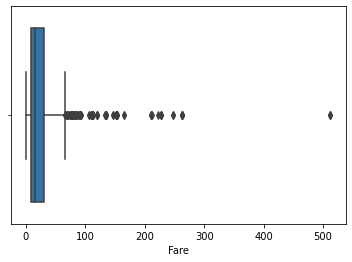

In [28]:
# visualizing outliers using box plots
sns.boxplot(x='Fare',data=df)

In [29]:

from scipy import stats

In [30]:
scores = np.array([300,320,400,425,-1,10000])

In [31]:
np.mean(scores)

1907.3333333333333

In [32]:
stats.trim_mean(scores,0.2)

361.25

In [33]:
np.mean(df['Fare'])

32.2042079685746

In [34]:
stats.trim_mean(df['Fare'],0.1)

21.37871556802244

## **Estimates of Variability**


Location is just one dimension in summarizing a feature. A second dimension, variability, also referred to as dispersion, measures whether the data values are tightly clustered or spread out. 


- The best-known estimates of variability are the variance and the standard deviation, which are based on squared deviations. The variance is an average of the squared deviations, and the standard deviation is the square root of the variance.

- The standard deviation is much easier to interpret than the variance since it is on the same scale as the original data

## **Standard Deviation**

Standard deviation is a measure that is used to quantify the amount of variation of a set of data values from its mean. A low standard deviation for a variable indicates that the data points tend to be close to its mean, and vice versa.

In [35]:
data_url = "/content/drive/MyDrive/Colab Notebooks/datasets/housing.csv"

In [36]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
boston_df = pd.read_csv(data_url,header=None,names=column_names,sep=r'\s+')

In [37]:
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [38]:
boston_df.std()

CRIM         8.601545
ZN          23.322453
INDUS        6.860353
CHAS         0.253994
NOX          0.115878
RM           0.702617
AGE         28.148861
DIS          2.105710
RAD          8.707259
TAX        168.537116
PTRATIO      2.164946
B           91.294864
LSTAT        7.141062
MEDV         9.197104
dtype: float64

- Low standard deviation means data are clustered around the mean, and high standard deviation indicates data are more spread out. 

- A standard deviation close to zero indicates that data points are close to the mean, whereas a high or low standard deviation indicates data points are respectively above or below the mean.

- Smaller values indicate that the data points cluster closer to the mean—the values in the dataset are relatively consistent. 

- Conversely, higher values signify that the values spread out further from the mean. Data values become more dissimilar, and extreme values become more likely.

## **Variance**

Variance is another measure of dispersion. It is the square of the standard deviation and the covariance of the random variable with itself.

In [39]:
boston_df.head(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.9,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.9,9.14,21.6


In [40]:
boston_df.var()

CRIM          73.986578
ZN           543.936814
INDUS         47.064442
CHAS           0.064513
NOX            0.013428
RM             0.493671
AGE          792.358399
DIS            4.434015
RAD           75.816366
TAX        28404.759488
PTRATIO        4.686989
B           8334.752263
LSTAT         50.994760
MEDV          84.586724
dtype: float64

## **Interquartile Range (IQR)**


Quartile, as its name sounds, is a statistical term which divides the data into quarters or four defined intervals. It basically divides the data points into a data set in 4 quarters on the number line. One thing we need to keep in mind is that data points can be random and we have to put those number in line first on the number line in ascending order and then divide them into quartiles. It is basically an extended version of the median. Median divides the data into two equal parts which quartiles divide it into four parts. Once we divide the data, the four quartiles will be:

- 1st quartile or lower quartile basically separate the lowest 25% of data from the highest 75%.
- 2nd quartile or middle quartile also same as median it divides numbers - into 2 equal parts.
- 3rd quartile or the upper quartile separate the highest 25% of data from the lowest 75%.


Range: 

It is the difference between the largest value and the smallest value in the given data set.


Interquartile Range :

the interquartile range is the range of the middle 50% of the data.

IQR = Q3 – Q1


Uses:

- The IQR is used to build box plots, simple graphical representations of a probability distribution.
- The IQR can also be used to identify the outliers in the given data set.
- The IQR gives the central tendency of the data.

Decision Making

- The data set has a higher value of interquartile range (IQR) has more variability.
- The data set having a lower value of interquartile range (IQR) is preferable.

In [41]:
data = [32, 36, 46, 47, 56, 69, 75, 79, 79, 88, 89, 91, 92, 93, 96, 97,101, 105, 112, 116]

q1 = np.percentile(data,25,interpolation='midpoint')
q3 = np.percentile(data,75,interpolation='midpoint')

In [42]:
q1,q3

(62.5, 96.5)

In [43]:
iqr = q3-q1

In [44]:
iqr

34.0

**NOTE: outliers are value below: q1 - 1.5*IQR and value above q3 + 1.5 * IQR** 

# **Exploring the Data Distribution**


Each of the estimates we’ve covered sums up the data in a single number to describe the location or variability of the data. It is also useful to explore how the data is distributed overall.


## **Percentiles and BoxPlots**

A boxplot is a graph that gives you a good indication of how the values in the data are spread out. Although boxplots may seem primitive in comparison to a histogram or density plot, they have the advantage of taking up less space, which is useful when comparing distributions between many groups or datasets.


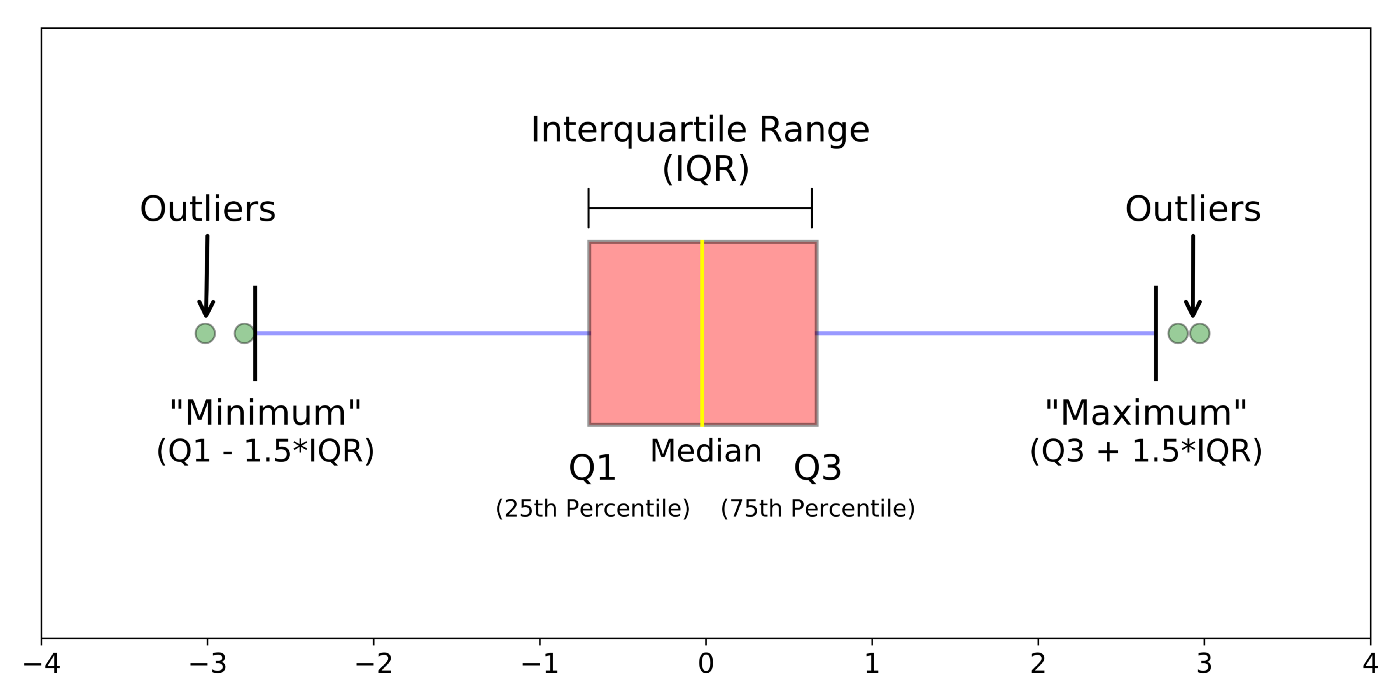



Boxplots are a standardized way of displaying the distribution of data based on a five number summary (“minimum”, first quartile (Q1), median, third quartile (Q3), and “maximum”).


- median (Q2/50th Percentile): the middle value of the dataset.
- first quartile (Q1/25th Percentile): the middle number between the smallest number (not the “minimum”) and the median of the dataset.
- third quartile (Q3/75th Percentile): the middle value between the median and the highest value (not the “maximum”) of the dataset.
- interquartile range (IQR): 25th to the 75th percentile.
whiskers (shown in blue)
outliers (shown as green circles)
- “maximum”: Q3 + 1.5*IQR
- “minimum”: Q1 -1.5*IQR

In [45]:
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [46]:
boston_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [47]:
boston_df.quantile([0.25,0.5,0.75])

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0.25,0.082045,0.0,5.19,0.0,0.449,5.8855,45.025,2.100175,4.0,279.0,17.40,375.3775,6.950,17.025
0.50,0.256510,0.0,9.69,0.0,0.538,6.2085,77.500,3.207450,5.0,330.0,19.05,391.4400,11.360,21.200
0.75,3.677082,12.5,18.10,0.0,0.624,6.6235,94.075,5.188425,24.0,666.0,20.20,396.2250,16.955,25.000


In [48]:
boston_df.quantile([0.25,0.5,0.75])["AGE"]

0.25    45.025
0.50    77.500
0.75    94.075
Name: AGE, dtype: float64

In [49]:
boston_df['AGE'].std()

28.148861406903638

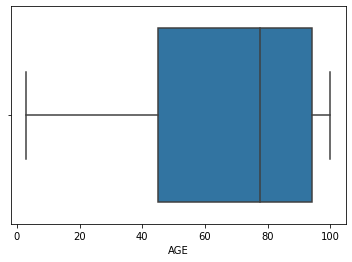

In [50]:
ax = sns.boxplot(x="AGE",data=boston_df)

In [51]:
boston_df.quantile([0.25,0.5,0.75])["CRIM"]

0.25    0.082045
0.50    0.256510
0.75    3.677082
Name: CRIM, dtype: float64

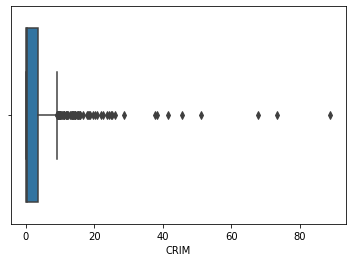

In [52]:
ax = sns.boxplot(x="CRIM",data=boston_df)

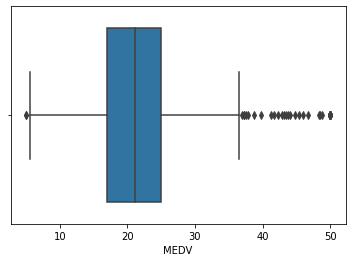

In [53]:
ax = sns.boxplot(x='MEDV',data=boston_df)

## **Frequency Tables and Histograms**

Use histograms when you have continuous measurements and want to understand the distribution of values and look for outliers. These graphs take your continuous measurements and place them into ranges of values known as bins. Each bin has a bar that represents the count or percentage of observations that fall within that bin.

**Histograms and the Central Tendency**

In [54]:
boston_df.std()

CRIM         8.601545
ZN          23.322453
INDUS        6.860353
CHAS         0.253994
NOX          0.115878
RM           0.702617
AGE         28.148861
DIS          2.105710
RAD          8.707259
TAX        168.537116
PTRATIO      2.164946
B           91.294864
LSTAT        7.141062
MEDV         9.197104
dtype: float64

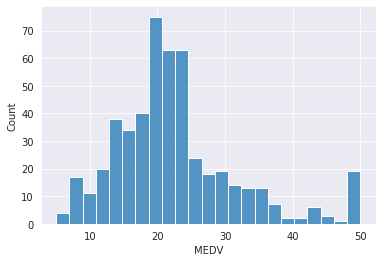

In [55]:
sns.set_style('darkgrid')
sns.histplot(x='MEDV',data=boston_df)

In [56]:
np.mean(boston_df['MEDV'])

22.532806324110698

Using Histograms to Identify Outliers

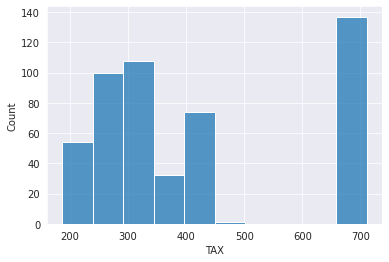

In [57]:
sns.histplot(x='TAX',data=boston_df)